<a href="https://colab.research.google.com/github/vishwa24816/Timesfm-prediction/blob/main/Timesfm%20prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q timesfm[torch] yfinance pandas numpy matplotlib seaborn
import numpy as np, pandas as pd, yfinance as yf, torch, timesfm
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
TICKER, START, SPLIT, END = "^GSPC", "2005-01-01", "2020-01-01", "2025-12-31"
raw = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
close = raw["Close"]
close = close.squeeze() if isinstance(close, pd.DataFrame) else close
close.index = pd.to_datetime(close.index).tz_localize(None)
print(close.shape, close.index.min().date(), close.index.max().date())

(5282,) 2005-01-03 2025-12-30


In [3]:
try:
    monthly = close.resample("ME").last().dropna()
except ValueError:
    monthly = close.resample("M").last().dropna()
train  = monthly[monthly.index < SPLIT]
actual = monthly[monthly.index >= SPLIT]
HORIZON = len(actual)
print(len(train), HORIZON)

180 72


In [4]:
torch.set_float32_matmul_precision("high")
model = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
model.compile(timesfm.ForecastConfig(
    max_context=1024, max_horizon=128, normalize_inputs=True,
    use_continuous_quantile_head=True, force_flip_invariance=True,
    infer_is_positive=True, fix_quantile_crossing=True))

config.json:   0%|          | 0.00/475 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  925MB            

model.safetensors: downloading bytes:           |  0.00B            

In [5]:
point, quant = model.forecast(horizon=HORIZON, inputs=[train.values.astype(float)])
point, quant = np.asarray(point)[0], np.asarray(quant)[0]

In [6]:
cmp = pd.DataFrame({"actual": actual.values, "predicted": point,
                    "q10": quant[:, 1], "q90": quant[:, 9]}, index=actual.index)
cmp["error"] = cmp.predicted - cmp.actual
cmp["abs_error"] = cmp.error.abs()
cmp["pct_error"] = cmp.error / cmp.actual * 100
cmp["cum_abs_pct"] = cmp.abs_error.expanding().mean() / cmp.actual.expanding().mean() * 100
cmp.round(2).head()

,actual,predicted,q10,q90,error,abs_error,pct_error,cum_abs_pct
Date,,,,,,,,
2020-01-31,3225.52,3218.889893,3090.250000,3283.719971,-6.63,6.63,-0.21,0.21
2020-02-29,2954.22,3194.909912,3049.010010,3304.790039,240.69,240.69,8.15,4.00
2020-03-31,2584.59,3191.530029,3012.050049,3321.270020,606.94,606.94,23.48,9.75
2020-04-30,2912.43,3179.209961,2965.310059,3337.320068,266.78,266.78,9.16,9.60
2020-05-31,3044.31,3220.209961,2998.149902,3379.669922,175.90,175.90,5.78,8.81


In [7]:
a, p, e = cmp.actual.values, cmp.predicted.values, cmp.error.values
last_train, yrs = train.iloc[-1], HORIZON / 12
kpi = {
    "MAE": np.mean(np.abs(e)),
    "RMSE": np.sqrt(np.mean(e**2)),
    "MAPE %": np.mean(np.abs(e / a)) * 100,
    "sMAPE %": np.mean(2*np.abs(e) / (np.abs(a) + np.abs(p))) * 100,
    "Bias": e.mean(),
    "R2": 1 - np.sum(e**2) / np.sum((a - a.mean())**2),
    "Correlation": np.corrcoef(a, p)[0, 1],
    "Directional accuracy %": np.mean(np.sign(np.diff(np.r_[last_train, a])) ==
                                      np.sign(np.diff(np.r_[last_train, p]))) * 100,
    "80% interval coverage %": ((cmp.actual >= cmp.q10) & (cmp.actual <= cmp.q90)).mean() * 100,
    "Actual CAGR %": ((a[-1] / last_train) ** (1/yrs) - 1) * 100,
    "Predicted CAGR %": ((p[-1] / last_train) ** (1/yrs) - 1) * 100,
    "Final-month gap %": (p[-1] - a[-1]) / a[-1] * 100,
}
kpi_df = pd.DataFrame(kpi, index=["value"]).T.round(2)
display(kpi_df)

,value
MAE,1262.09
RMSE,1557.22
MAPE %,24.54
sMAPE %,29.17
Bias,-1223.53
R2,-1.21
Correlation,0.87
Directional accuracy %,62.50
80% interval coverage %,9.72
Actual CAGR %,13.47


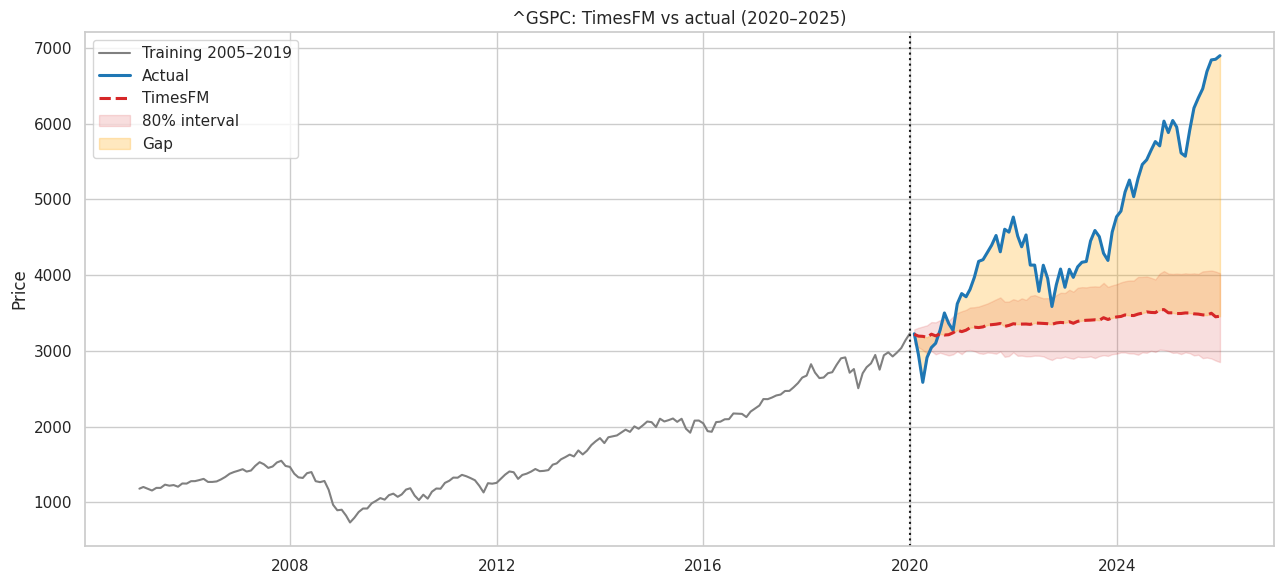

In [8]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(train.index, train.values, color="gray", label="Training 2005–2019")
ax.plot(cmp.index, cmp.actual, color="#1f77b4", lw=2.2, label="Actual")
ax.plot(cmp.index, cmp.predicted, color="#d62728", lw=2.2, ls="--", label="TimesFM")
ax.fill_between(cmp.index, cmp.q10, cmp.q90, color="#d62728", alpha=0.15, label="80% interval")
ax.fill_between(cmp.index, cmp.actual, cmp.predicted, color="orange", alpha=0.25, label="Gap")
ax.axvline(pd.Timestamp(SPLIT), color="k", ls=":")
ax.set(title=f"{TICKER}: TimesFM vs actual (2020–2025)", ylabel="Price")
ax.legend(); plt.tight_layout(); plt.show()

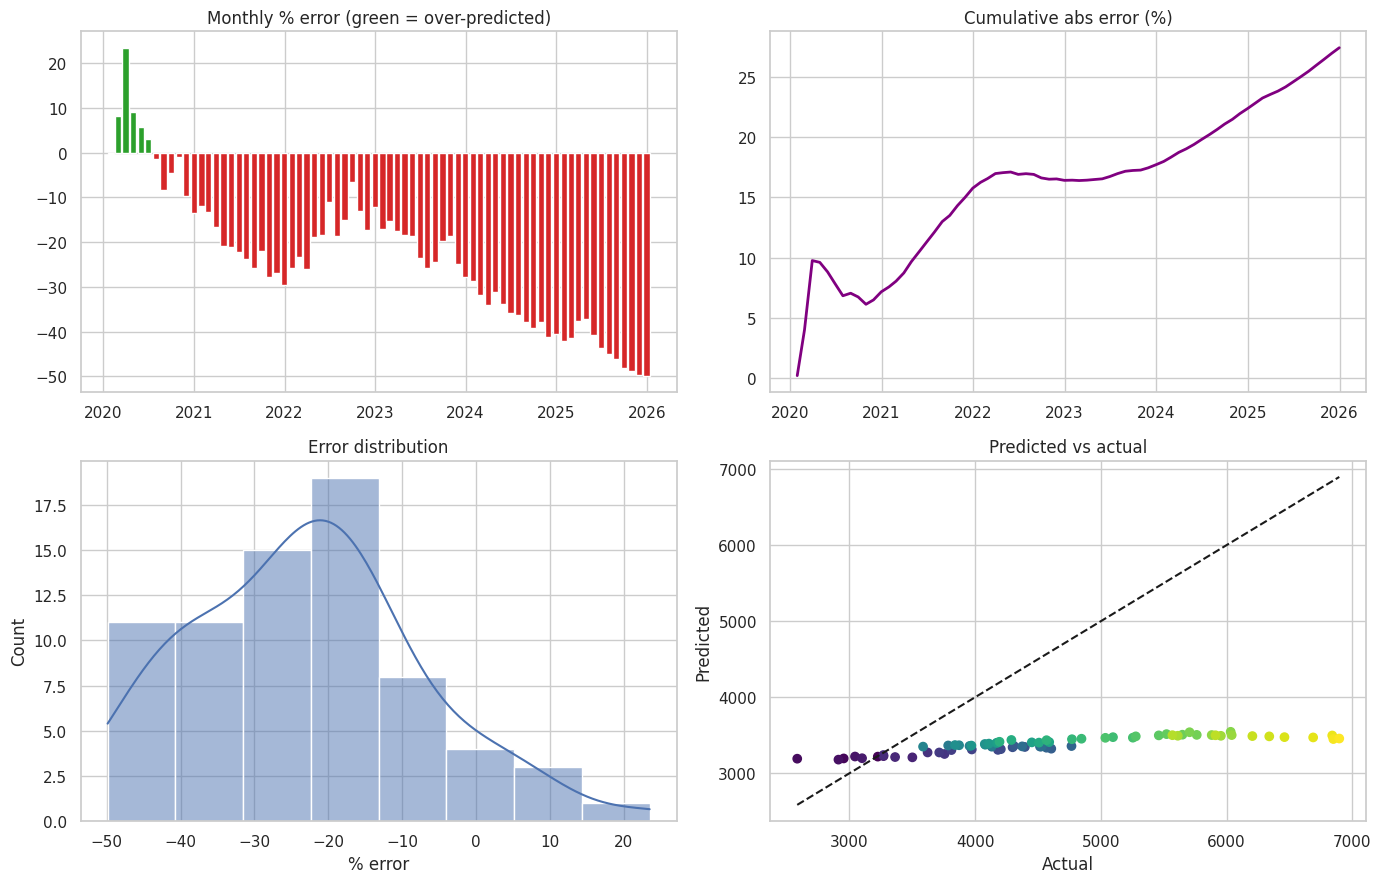

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
axs[0,0].bar(cmp.index, cmp.pct_error, width=25,
             color=np.where(cmp.pct_error >= 0, "#2ca02c", "#d62728"))
axs[0,0].set(title="Monthly % error (green = over-predicted)")
axs[0,1].plot(cmp.index, cmp.cum_abs_pct, color="purple", lw=2)
axs[0,1].set(title="Cumulative abs error (%)")
sns.histplot(cmp.pct_error, kde=True, ax=axs[1,0])
axs[1,0].set(title="Error distribution", xlabel="% error")
axs[1,1].scatter(cmp.actual, cmp.predicted, c=np.arange(HORIZON), cmap="viridis")
lims = [min(a.min(), p.min()), max(a.max(), p.max())]
axs[1,1].plot(lims, lims, "k--")
axs[1,1].set(title="Predicted vs actual", xlabel="Actual", ylabel="Predicted")
plt.tight_layout(); plt.show()

,actual_avg,predicted_avg,MAE,mean_pct_error,gap_%
Date,,,,,
2020,3216.95,3218.080078,230.21,0.95,0.04
2021,4278.76,3327.770020,950.99,-21.84,-22.23
2022,4077.66,3360.719971,716.93,-17.19,-17.58
2023,4322.65,3407.959961,914.69,-20.95,-21.16
2024,5460.22,3496.669922,1963.55,-35.72,-35.96
2025,6280.52,3484.360107,2796.16,-44.21,-44.52


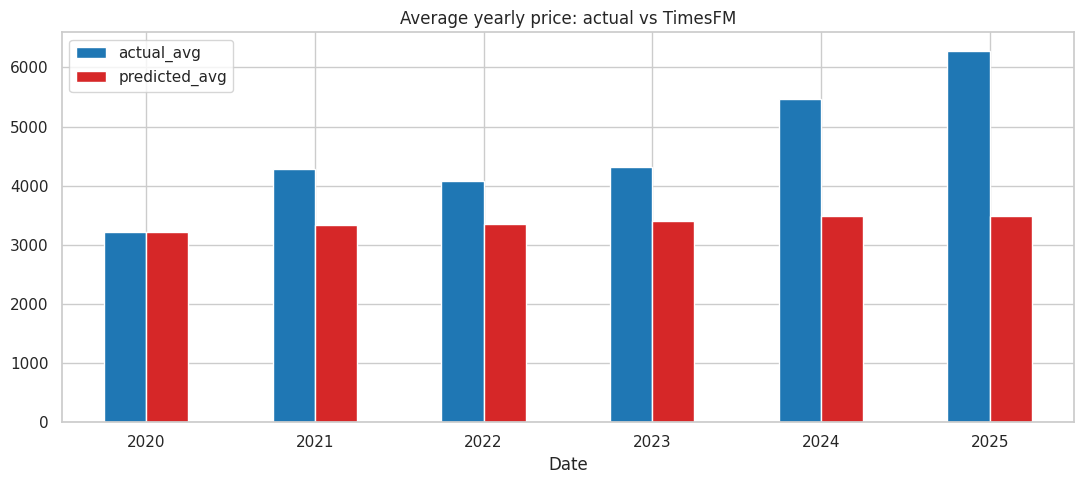

In [10]:
yearly = cmp.groupby(cmp.index.year).agg(
    actual_avg=("actual", "mean"), predicted_avg=("predicted", "mean"),
    MAE=("abs_error", "mean"), mean_pct_error=("pct_error", "mean"))
yearly["gap_%"] = (yearly.predicted_avg - yearly.actual_avg) / yearly.actual_avg * 100
display(yearly.round(2))
yearly[["actual_avg", "predicted_avg"]].plot(kind="bar", figsize=(11, 5),
                                             color=["#1f77b4", "#d62728"])
plt.title("Average yearly price: actual vs TimesFM"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
cmp.to_csv("timesfm_vs_actual.csv"); kpi_df.to_csv("timesfm_kpis.csv")